# Notebook 05 ? Real DAS Signal Analysis

## GeoWaveAI

**Dataset:** DeepSubDAS  
**Recording:** 20211102T152000_patch1_highnoise_30_100_0_100.h5

This notebook investigates the actual DAS waveform using numerical analysis and visualization.

The analysis uses channel indices and sample indices. The individual file's sampling frequency and physical channel spacing have not yet been independently verified.

**Important:** This notebook performs exploratory signal analysis. It does not identify confirmed earthquake events or train a machine-learning model.


## 1. Research Objectives

We will investigate:

1. The numerical structure of the real DAS recording.
2. Amplitude characteristics across channels.
3. Differences between individual channel waveforms.
4. Signal amplitude distributions.
5. Changes in signal energy across sample indices.
6. Channels and sample regions with unusual amplitude characteristics.

We will preserve the original recording and perform all analysis in memory.


In [1]:
from pathlib import Path

import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("Scientific libraries imported successfully.")
print("NumPy version:", np.__version__)
print("Pandas version:", pd.__version__)


Scientific libraries imported successfully.
NumPy version: 2.5.4
Pandas version: 3.1.0


## 2. Locate the Project and Dataset

The dataset is stored inside `data/raw/deepsubdas/`.

We locate the project root by finding its `pyproject.toml` file. This avoids depending on the notebook's current working directory.


In [2]:
current_path = Path.cwd().resolve()

project_root = next(
    (p for p in [current_path, *current_path.parents]
     if (p / "pyproject.toml").exists()),
    None
)

if project_root is None:
    raise FileNotFoundError(
        "Could not locate the GeoWaveAI project root."
    )

dataset_path = (
    project_root
    / "data"
    / "raw"
    / "deepsubdas"
    / "20211102T152000_patch1_highnoise_30_100_0_100.h5"
)

print("Project root:", project_root)
print("Dataset path:", dataset_path)
print("Dataset exists:", dataset_path.exists())

if not dataset_path.exists():
    raise FileNotFoundError(
        f"DeepSubDAS recording not found: {dataset_path}"
    )


Project root: E:\GeoWaveAI\geowaveai
Dataset path: E:\GeoWaveAI\geowaveai\data\raw\deepsubdas\20211102T152000_patch1_highnoise_30_100_0_100.h5
Dataset exists: True


## 3. Load the Real DAS Recording

The HDF5 file contains two datasets:

- `patch`: the DAS waveform.
- `mask`: three numerical annotation layers.

We will analyze the waveform first. We will not assign P-wave, S-wave, or noise meanings to the original HDF5 mask indices until their storage convention is independently verified.


In [3]:
with h5py.File(dataset_path, "r") as h5_file:
    print("HDF5 root keys:", list(h5_file.keys()))

    patch = h5_file["patch"][:]
    mask = h5_file["mask"][:]

print("\nWaveform loaded.")
print("Patch shape:", patch.shape)
print("Patch data type:", patch.dtype)
print("Mask shape:", mask.shape)
print("Mask data type:", mask.dtype)


HDF5 root keys: ['mask', 'patch']

Waveform loaded.
Patch shape: (300, 4000)
Patch data type: float32
Mask shape: (3, 300, 4000)
Mask data type: float64


## 4. Validate the Recording

Before calculating statistics, check the array dimensions and numerical values.

Expected structure from our previous investigation:

- 300 channels.
- 4000 samples per channel.
- All waveform values should be finite.


In [4]:
print("Number of dimensions:", patch.ndim)
print("Number of channels:", patch.shape[0])
print("Samples per channel:", patch.shape[1])

print("\nNumerical validation")
print("All values finite:", np.isfinite(patch).all())
print("NaN values:", np.isnan(patch).sum())
print("Positive infinity:", np.isposinf(patch).sum())
print("Negative infinity:", np.isneginf(patch).sum())

if patch.ndim != 2:
    raise ValueError("Expected a two-dimensional DAS waveform.")

if not np.isfinite(patch).all():
    raise ValueError("The waveform contains invalid numerical values.")


Number of dimensions: 2
Number of channels: 300
Samples per channel: 4000

Numerical validation
All values finite: True
NaN values: 0
Positive infinity: 0
Negative infinity: 0


## 5. Overall Waveform Statistics

These statistics describe the complete recording.

Amplitude values are reported in the numerical units stored in the HDF5 file. Their physical measurement units have not been verified.


In [5]:
overall_stats = pd.Series({
    "Minimum": np.min(patch),
    "Maximum": np.max(patch),
    "Mean": np.mean(patch),
    "Standard deviation": np.std(patch),
    "Median": np.median(patch),
    "Root mean square": np.sqrt(np.mean(patch ** 2)),
    "1st percentile": np.percentile(patch, 1),
    "99th percentile": np.percentile(patch, 99)
}, name="Value")

display(overall_stats.to_frame())


,Value
Minimum,-11.866403
Maximum,11.224660
Mean,-0.000765
Standard deviation,1.274881
Median,-0.001204
Root mean square,1.274881
1st percentile,-3.726515
99th percentile,3.704723


## 6. Visualize the Complete DAS Recording

The heatmap shows amplitude variation across channel and sample indices.

- Horizontal axis: sample index.
- Vertical axis: channel index.
- Color: waveform amplitude.

The color limits use the 99th percentile of absolute amplitude to make the central waveform structure easier to inspect. Values outside the display limits are not removed from the original data.


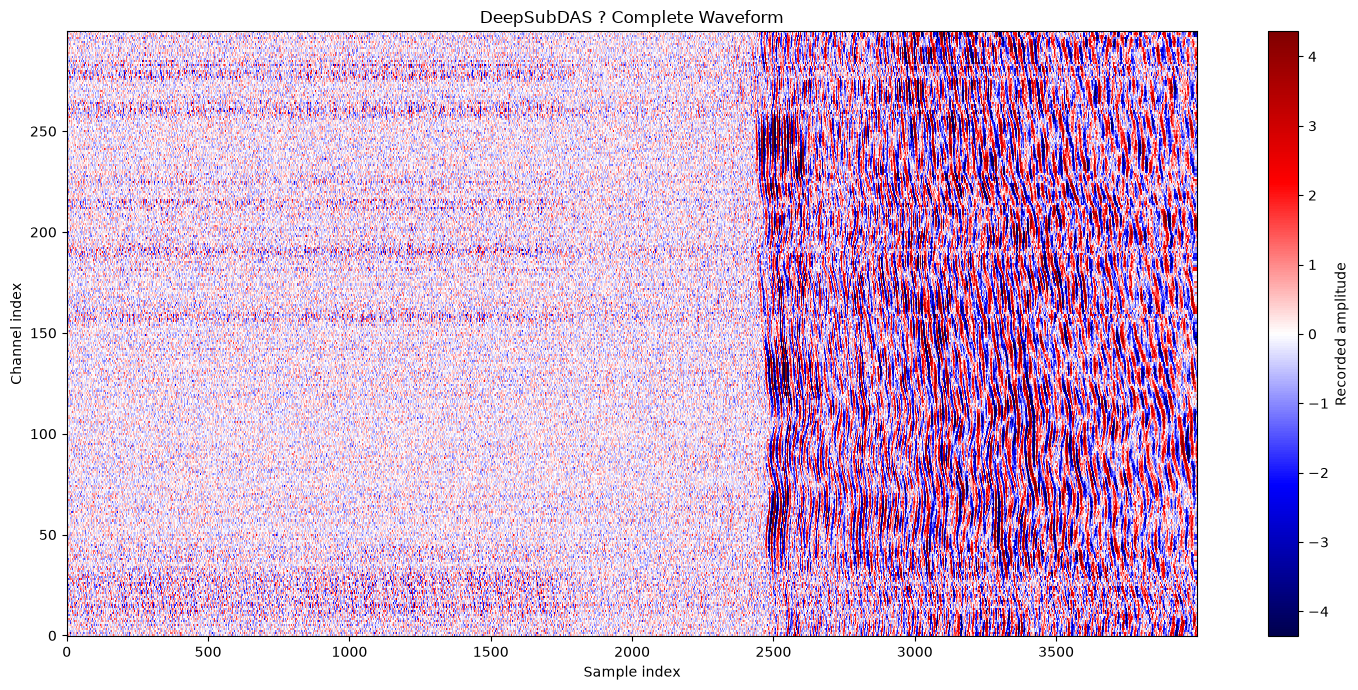

99th percentile absolute amplitude: 4.362408


In [6]:
display_limit = np.percentile(np.abs(patch), 99)

plt.figure(figsize=(15, 7))

plt.imshow(
    patch,
    aspect="auto",
    origin="lower",
    cmap="seismic",
    vmin=-display_limit,
    vmax=display_limit,
    interpolation="nearest"
)

plt.colorbar(label="Recorded amplitude")
plt.xlabel("Sample index")
plt.ylabel("Channel index")
plt.title("DeepSubDAS ? Complete Waveform")
plt.tight_layout()
plt.show()

print("99th percentile absolute amplitude:", display_limit)


## 7. Analyze Individual DAS Channels

We select five channels distributed evenly across the recording's channel indices.

This is a systematic selection, not a selection based on whether a channel looks interesting.

Each plot shows recorded amplitude against sample index.


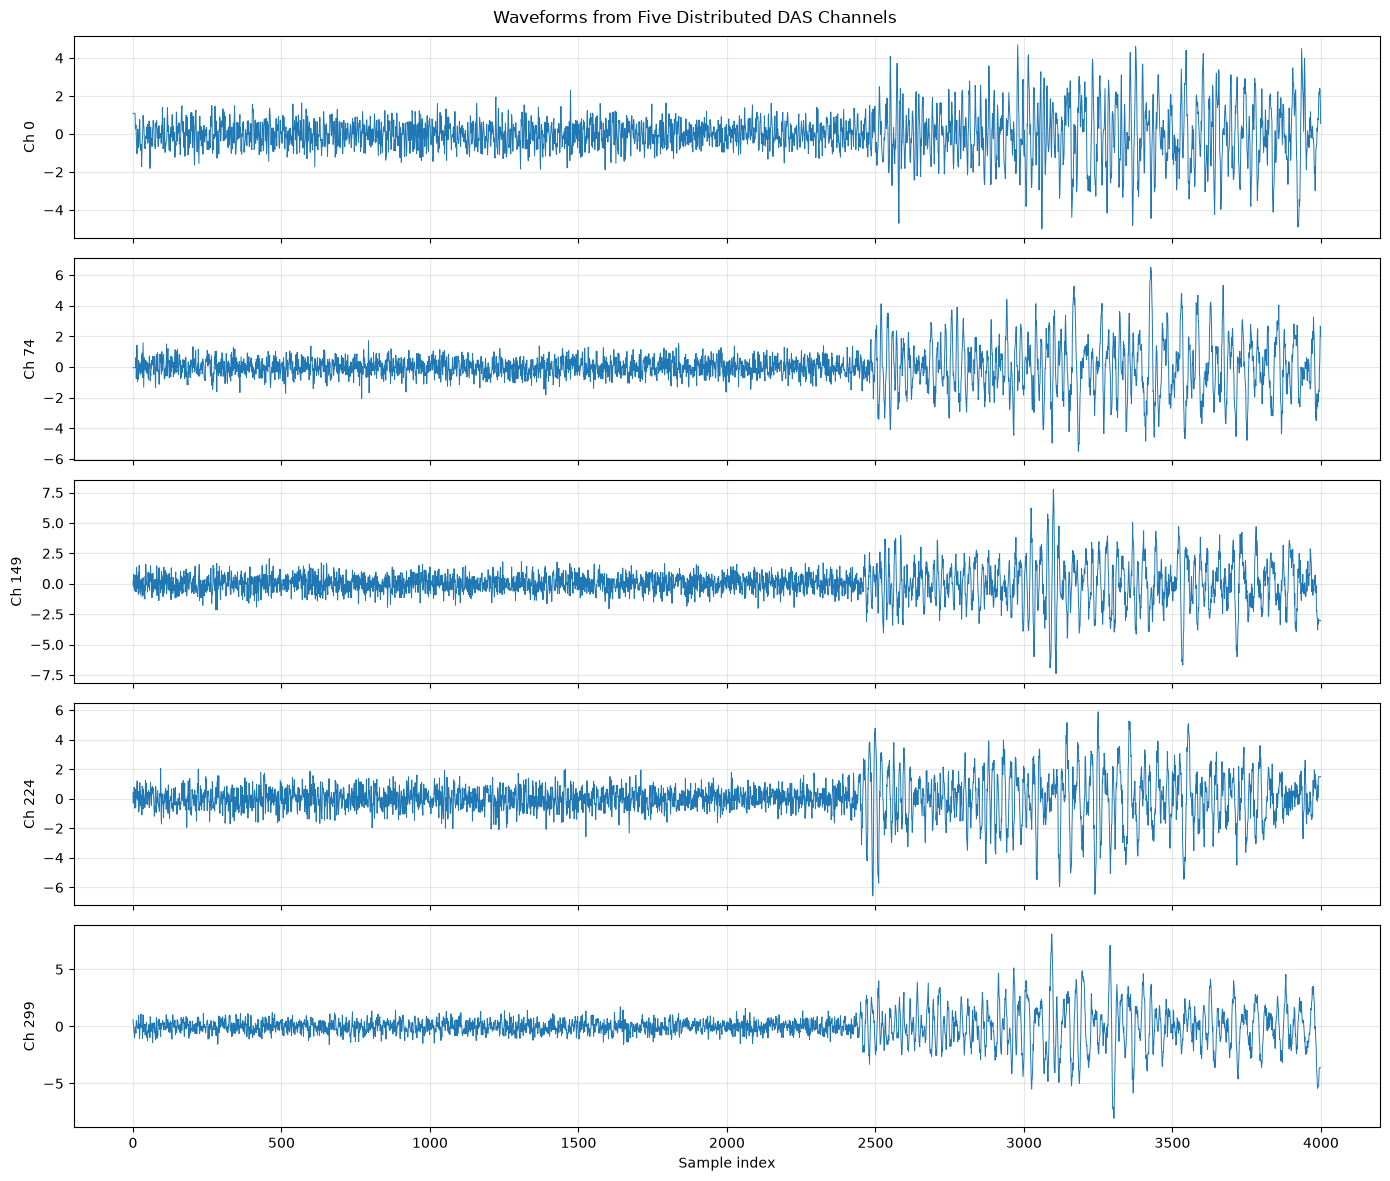

Selected channel indices: [0, 74, 149, 224, 299]


In [7]:
selected_channels = np.linspace(
    0, patch.shape[0] - 1, 5, dtype=int
)

fig, axes = plt.subplots(
    len(selected_channels), 1,
    figsize=(14, 12),
    sharex=True
)

for ax, channel_index in zip(axes, selected_channels):
    ax.plot(patch[channel_index], linewidth=0.7)
    ax.set_ylabel(f"Ch {channel_index}")
    ax.grid(alpha=0.3)

axes[-1].set_xlabel("Sample index")
fig.suptitle("Waveforms from Five Distributed DAS Channels")
plt.tight_layout()
plt.show()

print("Selected channel indices:", selected_channels.tolist())


## 8. Channel-Wise Statistical Analysis

Every channel is analyzed separately.

We calculate:

- Mean amplitude.
- Standard deviation.
- Minimum and maximum.
- Peak-to-peak amplitude.
- Root mean square amplitude.
- Median amplitude.
- 1st and 99th percentiles.

These measurements help us compare the numerical characteristics of different channels.


In [8]:
channel_stats = pd.DataFrame({
    "channel": np.arange(patch.shape[0]),
    "mean": np.mean(patch, axis=1),
    "std": np.std(patch, axis=1),
    "minimum": np.min(patch, axis=1),
    "maximum": np.max(patch, axis=1),
    "peak_to_peak": np.ptp(patch, axis=1),
    "rms": np.sqrt(np.mean(patch ** 2, axis=1)),
    "median": np.median(patch, axis=1),
    "p01": np.percentile(patch, 1, axis=1),
    "p99": np.percentile(patch, 99, axis=1)
})

display(channel_stats.head(10))

print("Total channels analyzed:", len(channel_stats))


,channel,mean,std,minimum,maximum,peak_to_peak,rms,median,p01,p99
0,0,-0.009518,1.135233,-5.000690,4.690743,9.691433,1.135273,-0.009205,-3.296669,3.156216
1,1,-0.004750,1.222407,-6.252241,4.781709,11.033951,1.222417,0.005256,-3.423884,3.285939
2,2,-0.000923,1.116321,-6.036798,4.844294,10.881092,1.116321,-0.003369,-3.078712,3.108088
3,3,0.015906,1.184121,-6.914989,5.808176,12.723164,1.184228,0.031531,-3.455454,3.315927
4,4,0.016448,1.181830,-5.846518,6.154975,12.001493,1.181944,0.009808,-3.453040,3.423434
5,5,-0.011212,1.160388,-5.291675,5.349856,10.641531,1.160442,-0.005351,-3.197407,3.191036
6,6,0.005449,1.158281,-5.431383,6.156005,11.587388,1.158294,-0.014233,-3.331569,3.838485
7,7,0.009046,1.105533,-5.223006,6.343721,11.566727,1.105570,0.004440,-2.860156,3.198726
8,8,-0.005290,1.104377,-5.751539,4.258679,10.010219,1.104390,-0.012415,-3.043314,3.178030
9,9,0.024413,1.115421,-7.512470,5.136173,12.648643,1.115688,0.007912,-3.267510,3.262502


Total channels analyzed: 300


## 9. Compare Channel Standard Deviations

Standard deviation measures how widely waveform amplitudes vary around their channel mean.

A larger value indicates greater amplitude variation. It does not automatically mean that a channel contains a seismic event.


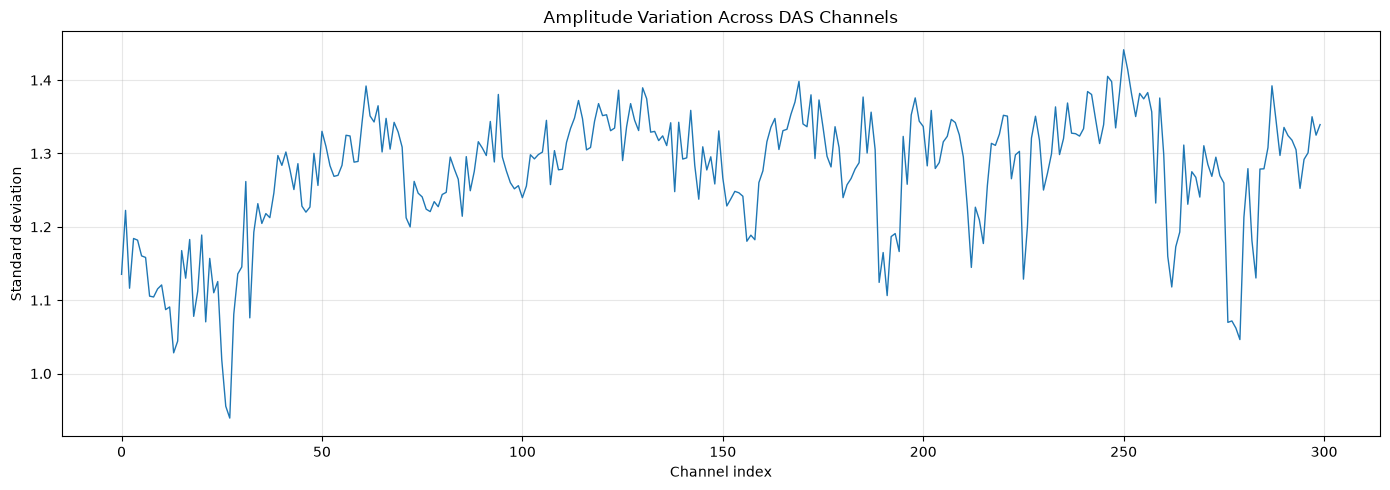

Minimum channel standard deviation: 0.93929976
Maximum channel standard deviation: 1.4413848


In [9]:
plt.figure(figsize=(14, 5))

plt.plot(
    channel_stats["channel"],
    channel_stats["std"],
    linewidth=1
)

plt.xlabel("Channel index")
plt.ylabel("Standard deviation")
plt.title("Amplitude Variation Across DAS Channels")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("Minimum channel standard deviation:",
      channel_stats["std"].min())

print("Maximum channel standard deviation:",
      channel_stats["std"].max())


## 10. Compare Channel RMS Amplitudes

RMS is the square root of the average squared amplitude.

It provides another measure of the overall signal magnitude in each channel.


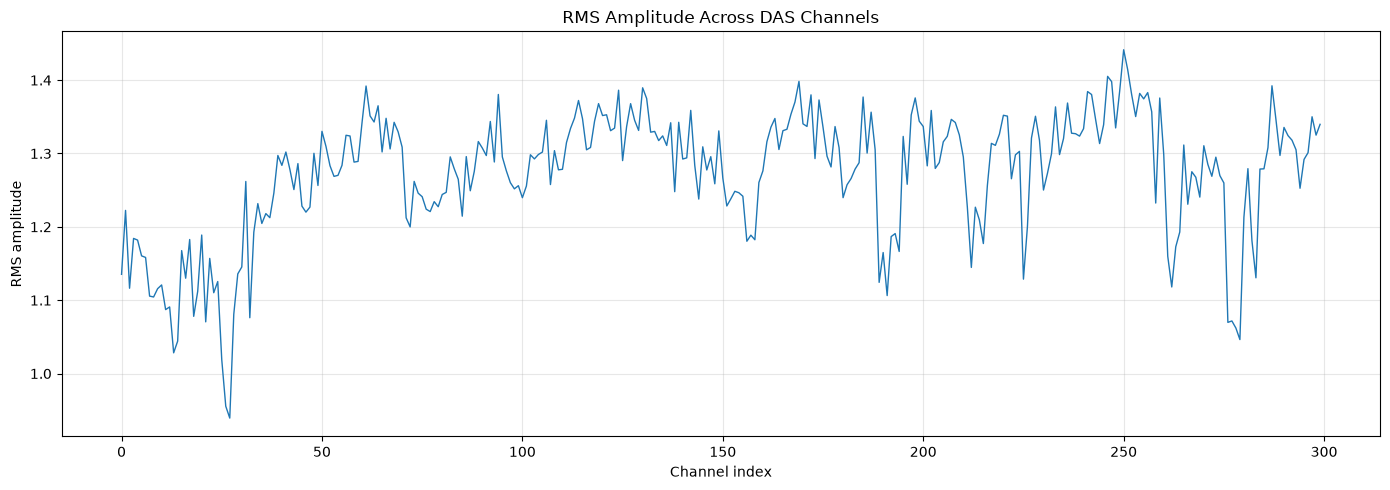

Minimum channel RMS: 0.93929976
Maximum channel RMS: 1.4414294


In [10]:
plt.figure(figsize=(14, 5))

plt.plot(
    channel_stats["channel"],
    channel_stats["rms"],
    linewidth=1
)

plt.xlabel("Channel index")
plt.ylabel("RMS amplitude")
plt.title("RMS Amplitude Across DAS Channels")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("Minimum channel RMS:", channel_stats["rms"].min())
print("Maximum channel RMS:", channel_stats["rms"].max())


## 11. Inspect the Amplitude Distribution

The histogram shows how frequently different waveform amplitudes occur throughout the recording.

This is a distribution of all stored waveform samples, not a probability distribution of earthquake events.


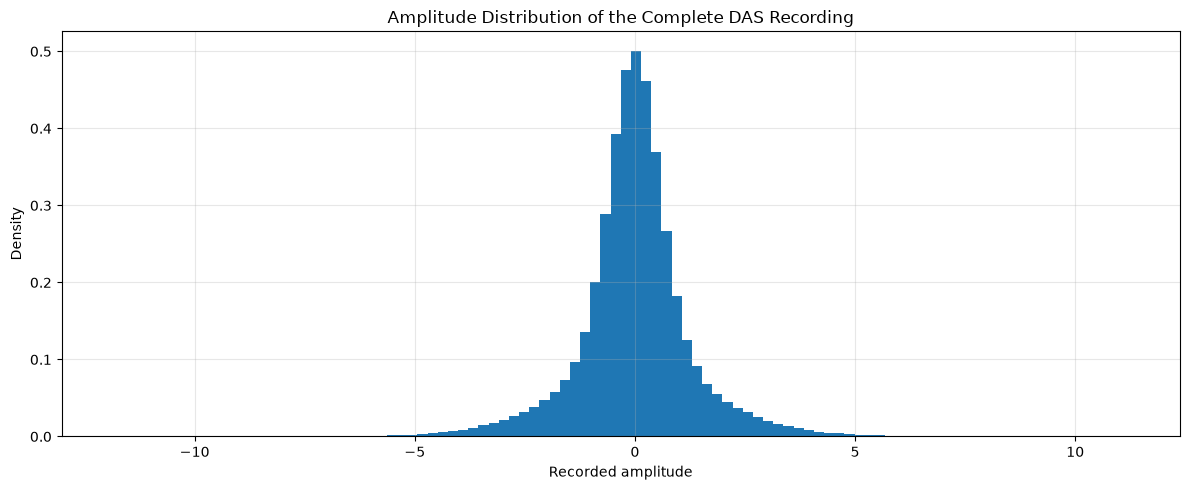

Total waveform samples: 1200000


In [11]:
plt.figure(figsize=(12, 5))

plt.hist(
    patch.ravel(),
    bins=100,
    density=True
)

plt.xlabel("Recorded amplitude")
plt.ylabel("Density")
plt.title("Amplitude Distribution of the Complete DAS Recording")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("Total waveform samples:", patch.size)


## 12. Compare Amplitude Distributions Across Channels

We compare the amplitude distributions of the five systematically selected channels.

A boxplot helps show their medians, spread, and potential extreme values.


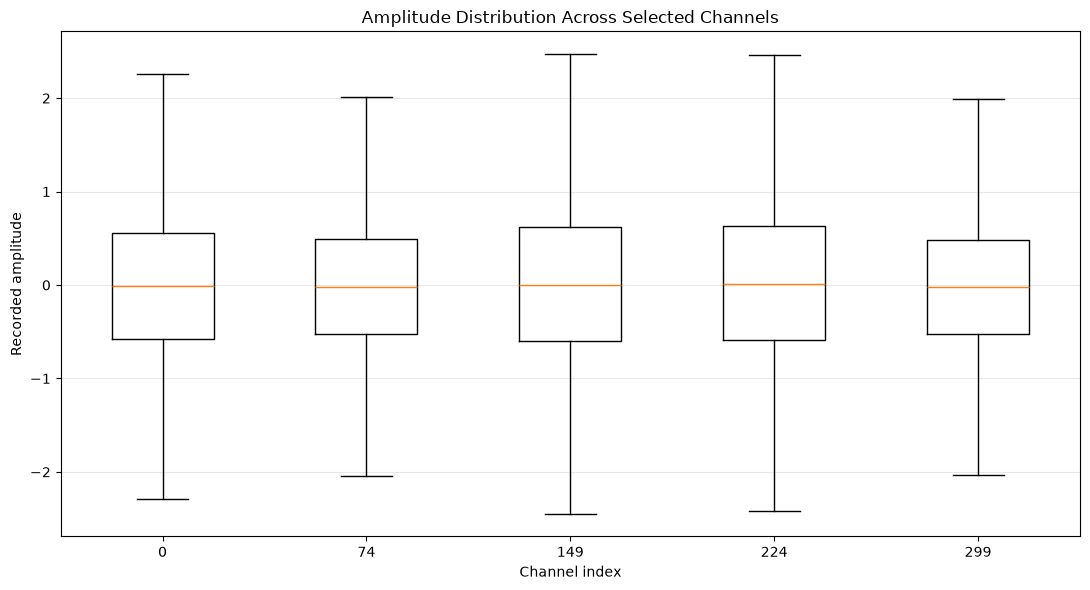

In [12]:
selected_data = [
    patch[channel_index]
    for channel_index in selected_channels
]

plt.figure(figsize=(11, 6))

plt.boxplot(
    selected_data,
    tick_labels=[str(i) for i in selected_channels],
    showfliers=False
)

plt.xlabel("Channel index")
plt.ylabel("Recorded amplitude")
plt.title("Amplitude Distribution Across Selected Channels")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


## 13. Analyze Signal Variation Across Sample Indices

For every sample index, we calculate:

- Mean absolute amplitude across channels.
- RMS amplitude across channels.

This helps us see how the overall recording magnitude changes along the sample dimension.

We do not convert sample indices into seconds because the individual file's sampling frequency is not yet independently verified.


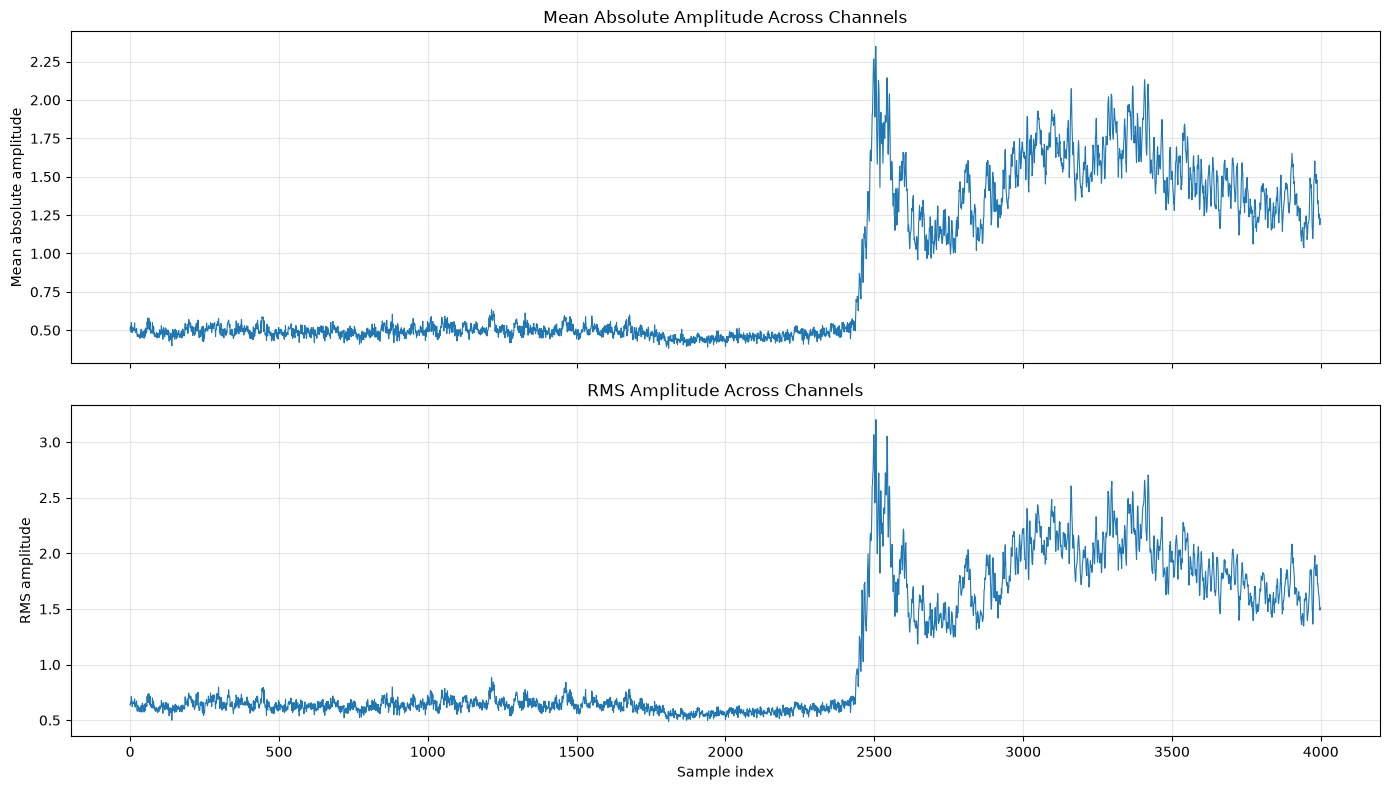

In [13]:
mean_absolute_by_sample = np.mean(
    np.abs(patch), axis=0
)

rms_by_sample = np.sqrt(
    np.mean(patch ** 2, axis=0)
)

fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)

axes[0].plot(mean_absolute_by_sample, linewidth=0.8)
axes[0].set_ylabel("Mean absolute amplitude")
axes[0].set_title("Mean Absolute Amplitude Across Channels")
axes[0].grid(alpha=0.3)

axes[1].plot(rms_by_sample, linewidth=0.8)
axes[1].set_ylabel("RMS amplitude")
axes[1].set_xlabel("Sample index")
axes[1].set_title("RMS Amplitude Across Channels")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()


## 14. Investigate High-Amplitude Sample Indices

We calculate the 99th percentile of the RMS profile across sample indices.

Sample indices above this threshold are flagged for further inspection.

**Important:** high amplitude alone does not establish the presence of an earthquake or a P/S arrival. These are exploratory amplitude-based indicators only.


99th percentile RMS threshold: 2.5625865
Number of flagged sample indices: 40

First 30 flagged sample indices:
[2493, 2494, 2495, 2496, 2497, 2498, 2499, 2500, 2501, 2503, 2504, 2505, 2506, 2507, 2514, 2515, 2516, 2522, 2537, 2538, 2539, 2541, 2542, 2543, 2544, 2545, 2550, 2551, 3161, 3162]


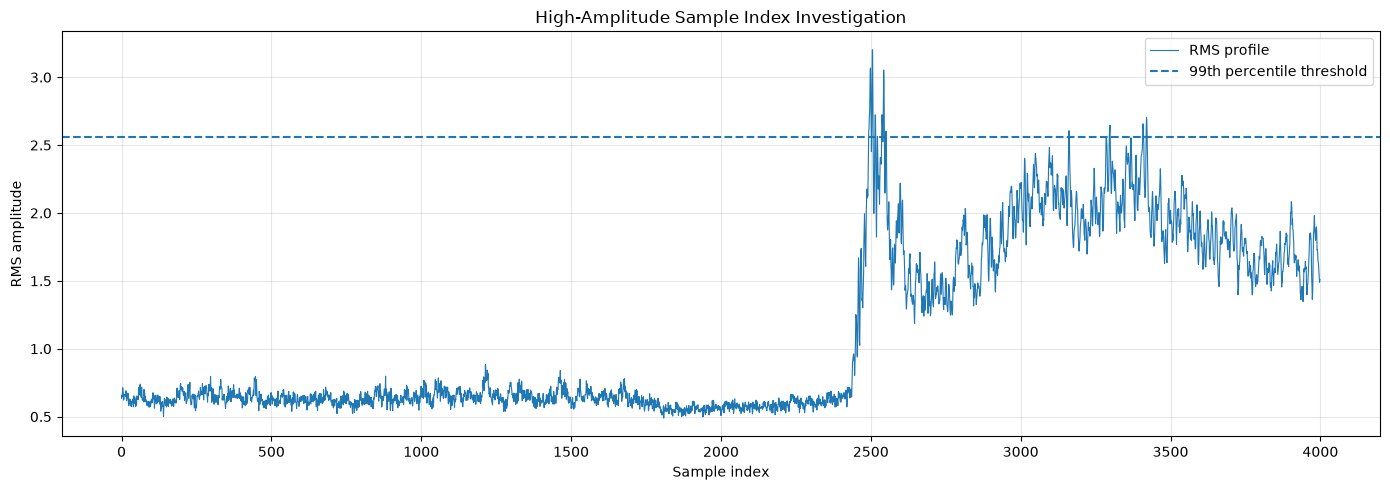

In [14]:
rms_threshold = np.percentile(rms_by_sample, 99)

high_amplitude_indices = np.where(
    rms_by_sample > rms_threshold
)[0]

print("99th percentile RMS threshold:", rms_threshold)
print("Number of flagged sample indices:",
      len(high_amplitude_indices))

print("\nFirst 30 flagged sample indices:")
print(high_amplitude_indices[:30].tolist())

plt.figure(figsize=(14, 5))

plt.plot(rms_by_sample, linewidth=0.8, label="RMS profile")
plt.axhline(
    rms_threshold,
    linestyle="--",
    label="99th percentile threshold"
)

plt.xlabel("Sample index")
plt.ylabel("RMS amplitude")
plt.title("High-Amplitude Sample Index Investigation")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


## 15. Identify Channels with the Largest RMS Values

We rank channels according to their RMS amplitude.

This is a numerical ranking, not a classification of good, bad, noisy, or seismic channels.


In [15]:
top_rms_channels = channel_stats.sort_values(
    "rms", ascending=False
).head(10)

display(
    top_rms_channels[
        ["channel", "mean", "std", "peak_to_peak", "rms"]
    ]
)


,channel,mean,std,peak_to_peak,rms
250,250,0.011336,1.441385,19.704990,1.441429
251,251,0.006073,1.414402,16.634094,1.414415
246,246,-0.002179,1.405143,20.994770,1.405144
169,169,-0.014284,1.398229,13.601906,1.398302
247,247,0.006380,1.397976,20.099873,1.397990
287,287,-0.015051,1.392215,14.246327,1.392297
61,61,0.000250,1.391968,15.679234,1.391968
130,130,0.011333,1.389511,20.787073,1.389557
124,124,-0.009056,1.386247,17.830875,1.386276
249,249,0.013548,1.384701,20.915157,1.384767


## 16. Research Observations

Review the outputs from this notebook before writing conclusions.

Questions to consider:

1. Does the complete waveform show variation across both dimensions?
2. Are channel standard deviations similar or substantially different?
3. Do the selected channels have similar amplitude distributions?
4. Does the RMS profile vary across sample indices?
5. Are high-amplitude sample indices concentrated in particular regions?
6. Which observations require additional investigation?

Do not describe an amplitude anomaly as an earthquake without independent phase or event evidence.


## 17. Limitations

This analysis has several limitations:

- The individual recording's sampling frequency remains unverified.
- Physical channel spacing and gauge length remain unverified.
- Physical measurement units remain unverified.
- The original HDF5 annotation layer ordering remains unresolved.
- High-amplitude regions are not automatically seismic events.
- No frequency-domain analysis is performed in this notebook.
- No filtering, event detection, or model training is performed here.

These limitations must be considered in future experiments.


## 18. Conclusion

This notebook provides an initial numerical and visual characterization of a real DeepSubDAS recording.

It examines waveform amplitudes across channels and sample indices, compares channel statistics, and identifies regions with relatively high RMS amplitude.

The results provide a foundation for later preprocessing and frequency-domain investigations.

All conclusions must be based on the actual outputs produced by this notebook. No unverified sampling frequency, physical unit, or annotation meaning should be assumed.
